# 03 · Pregunta 2a: afinidades entre películas

**Responsable:** Integrante C · **Plan:** ver `PLAN.md`

Si a un usuario le gusta una película (rating ≥ 4), ¿qué otras tienden a gustarle?

## Preparación

## 0. Preparación del entorno
En este apartado importamos las bibliotecas y los módulos del proyecto que utilizaremos. También configuramos la ruta principal del repositorio para poder acceder a las funciones desarrolladas en `src`, las herramientas principales serán `pandas` y `numpy` para la manipulación de datos y operaciones numéricas, y `matplotlib` para la visualización de resultados.

In [11]:
from pathlib import Path
import sys

# Busca la raíz del repo (la carpeta que contiene src/) sin importar desde dónde se abra el notebook.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import contratos, rutas
from src import limpieza, afinidades_peliculas

## Datos

Cargamos los conjuntos de datos de películas y calificaciones previamente procesados. El primero contiene información de los títulos disponibles, mientras que el segundo registra las calificaciones que los usuarios asignaron a cada película, verificamos que ambos conjuntos cumplan con la estructura esperada y revisamos sus dimensiones para conocer la información con la que trabajaremos.

In [12]:
movies, ratings = limpieza.datos_limpios()
contratos.verificar_esquema(movies, "movies")
contratos.verificar_esquema(ratings, "ratings")
print(movies.shape, ratings.shape)

(9742, 23) (100836, 5)


## 1. Matriz de gustos

Para estudiar las afinidades de gusto entre películas, construimos una matriz binaria usuario $\times$ película donde:
- **1.0:** si el usuario calificó la película con una nota $\ge 4.0$ (se considera que la película le gustó).
- **0.0:** si el usuario calificó la película con una nota $< 4.0$ (no le gustó o le fue indiferente).
- **NaN:** si el usuario no vio ni calificó la película.

### Consideraciones metodológicas clave:
1. **Un `NaN` NO es un cero:** Si imputáramos los valores ausentes con 0, estaríamos asumiendo que el hecho de no haber visto una película equivale a que no gustó. Como consecuencia, la correlación mediría qué películas se ven juntas (co-visualización dominada por la popularidad general) en lugar de medir qué películas *gustan* juntas. Al mantener `NaN`, la correlación se calcula estrictamente sobre los usuarios que efectivamente evaluaron ambas películas.
2. **Umbral de películas con $n \ge 100$:** Con el catálogo completo (9,742 películas), la inmensa mayoría de los pares de películas tiene entre 0 y 2 calificaciones en común, lo que hace imposible estimar correlaciones estables o produce coeficientes puramente espurios. Al restringirnos a las películas con al menos 100 calificaciones (138 películas que concentran una gran masa de ratings), garantizamos una base suficiente de usuarios compartidos ($min\_periods = 20$).


In [13]:
gustos = afinidades_peliculas.matriz_gustos(ratings, min_n=100)
contratos.verificar_matriz(gustos, "gusto")
display(gustos.head(10))
print(f"La matriz de gustos tiene {gustos.shape[0]} usuarios y {gustos.shape[1]} películas se redujo el numero de usuarios y películas al filtrar por un mínimo de 100 calificaciones por película.")
print("Algunos usuarios pueden haber no calificado algunas películas, por lo que la matriz puede contener NaN.")

movieId,1,10,1036,1073,1089,1097,110,111,1136,1193,...,736,7361,7438,778,780,79132,858,8961,912,924
userId,,,,,,,,,,,,,,,,,,,,,
1,1.0,NaN,NaN,1.0,1.0,1.0,1.0,NaN,1.0,NaN,...,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN
10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,NaN
100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
101,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
102,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
103,1.0,NaN,NaN,1.0,1.0,NaN,1.0,1.0,NaN,1.0,...,NaN,1.0,1.0,NaN,NaN,1.0,1.0,0.0,1.0,1.0
104,NaN,0.0,NaN,NaN,NaN,NaN,0.0,NaN,1.0,NaN,...,NaN,0.0,NaN,NaN,1.0,NaN,0.0,1.0,NaN,NaN
105,NaN,NaN,NaN,NaN,1.0,NaN,0.0,1.0,NaN,1.0,...,NaN,1.0,1.0,1.0,NaN,1.0,1.0,0.0,1.0,1.0
106,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


La matriz de gustos tiene 597 usuarios y 138 películas se redujo el numero de usuarios y películas al filtrar por un mínimo de 100 calificaciones por película.
Algunos usuarios pueden haber no calificado algunas películas, por lo que la matriz puede contener NaN.


## 2. Sesgo por usuario

Antes de estudiar las afinidades entre películas, analizaremos cómo se comportan los usuarios al momento de calificarlas.
No todos los usuarios tienen los mismos criterios de evaluación: algunos suelen otorgar calificaciones altas con mayor frecuencia, mientras que otros pueden ser más exigentes, calcularemos el porcentaje de calificaciones positivas de cada usuario, considerando como positivas aquellas iguales o superiores a 4 porterior a eso, utilizaremos estadísticas descriptivas para conocer la distribución de estos porcentajes e identificar qué tanta variación existe entre los usuarios.

In [ ]:
porcentaje_gustos =(
    ratings.assign(gusto=ratings["rating"] >= 4)
    .groupby("userId")["gusto"]
    .mean()*100
    )

display(porcentaje_gustos.head(20))
print(f"Las estadísticas de los porcentajes de gustos por usuario son:")
display(porcentaje_gustos.describe())

userId
1      86.206897
10     35.714286
100    72.297297
101    63.934426
102    35.714286
103    64.456233
104    46.520147
105    76.731302
106    72.727273
107    67.647059
108    67.105263
109    21.259843
11     64.062500
110    58.823529
111    39.473684
112    63.076923
113    61.333333
114    35.483871
115    65.178571
116    44.827586
Name: gusto, dtype: float64

Las estadísticas de los porcentajes de gustos por usuario son:


count    610.000000
mean      56.071262
std       20.229658
min        0.000000
25%       42.048055
50%       57.973654
75%       71.428571
max      100.000000
Name: gusto, dtype: float64

In [16]:
from IPython.display import display, Markdown

estadisticas = porcentaje_gustos.describe()

display(Markdown(f"""
### Sesgo por usuario

Se analizaron **{int(estadisticas['count'])} usuarios**.

El porcentaje promedio de calificaciones iguales o superiores a 4 fue de
**{estadisticas['mean']:.2f}%**, con una desviación estándar de
**{estadisticas['std']:.2f} puntos porcentuales**.

Los porcentajes van desde **{estadisticas['min']:.2f}%**
hasta **{estadisticas['max']:.2f}%**.

Esto muestra que existen diferencias entre los usuarios al momento de
calificar películas. Por lo tanto, definir que una película gustó cuando
su calificación fue mayor o igual a 4 puede representar distintos niveles
de satisfacción dependiendo del usuario.
"""))


### Sesgo por usuario

Se analizaron **610 usuarios**.

El porcentaje promedio de calificaciones iguales o superiores a 4 fue de
**56.07%**, con una desviación estándar de
**20.23 puntos porcentuales**.

Los porcentajes van desde **0.00%**
hasta **100.00%**.

Esto muestra que existen diferencias entre los usuarios al momento de
calificar películas. Por lo tanto, definir que una película gustó cuando
su calificación fue mayor o igual a 4 puede representar distintos niveles
de satisfacción dependiendo del usuario.


## 3. Correlación entre películas

Una vez construida la matriz de gustos, calcularemos la correlación entre las preferencias de los usuarios por cada pareja de películas, nos permitirá identificar si los usuarios que disfrutan una película tienden a mostrar un comportamiento similar respecto a otra.

Utilizaremos la correlación de Pearson sobre las variables binarias de la matriz de gustos, estableceremos un mínimo de 20 usuarios que hayan calificado ambas películas, evitando calcular correlaciones con muy pocas observaciones.

También revisaremos cuántas parejas cuentan con una correlación definida y sustituiremos los identificadores de las películas por sus respectivos títulos para facilitar la interpretación.

**Interpretación de las correlaciones**

- **Correlación cercana a 1:** los usuarios tienden a coincidir en sus gustos por ambas películas.
- **Correlación cercana a 0:** no se observa una relación lineal importante entre sus patrones de aceptación.
- **Correlación cercana a -1:** los usuarios que suelen disfrutar una película tienden a no disfrutar la otra, y viceversa.

<small>**Es importante recordar que una correlación no implica causalidad ni representa directamente la probabilidad de que una persona disfrute una película</small>**

In [17]:
# TODO: corr con min_periods; cuántos pares quedan con correlación definida
correlaciones = gustos.corr(min_periods=20)
correlaciones_titulos = correlaciones.rename(
    index=movies.set_index("movieId")["title"],
    columns=movies.set_index("movieId")["title"]
)

display(correlaciones_titulos.iloc[:5, :5])

# Contar pares con correlación definida (sin diagonal ni duplicados)
n_pares_definidos = correlaciones.where(
    np.triu(np.ones(correlaciones.shape), k=1).astype(bool)
).stack().count()

print("Dimensiones de la matriz:", correlaciones.shape)
print("Pares con correlación definida:", n_pares_definidos)

movieId,Toy Story (1995),GoldenEye (1995),Die Hard (1988),Willy Wonka & the Chocolate Factory (1971),Reservoir Dogs (1992)
movieId,,,,,
Toy Story (1995),1.000000,-0.143849,0.312938,0.210259,0.196125
GoldenEye (1995),-0.143849,1.000000,0.122279,-0.091287,0.132345
Die Hard (1988),0.312938,0.122279,1.000000,-0.058461,0.276041
Willy Wonka & the Chocolate Factory (1971),0.210259,-0.091287,-0.058461,1.000000,0.218575
Reservoir Dogs (1992),0.196125,0.132345,0.276041,0.218575,1.000000


Dimensiones de la matriz: (138, 138)
Pares con correlación definida: 9245


Las correlaciones permiten identificar películas cuyos patrones de aceptación son similares entre los usuarios. Los resultados muestran que algunas de las afinidades más fuertes se presentan entre películas de una misma saga, como *El Señor de los Anillos*, *Harry Potter* y *Kill Bill*. Esto sugiere que quienes disfrutan una película de estas franquicias suelen tener una tendencia similar respecto a sus continuaciones, una correlación alta no significa necesariamente que exista una probabilidad igual de alta de que alguien disfrute una película por haber disfrutado otra. Por lo que utilizaremos las probabilidades condicionales en el siguiente apartado para analizar de manera más directa qué otras películas tienden a gustarles a quienes disfrutan una película determinada.

## 4. Pares con mayor afinidad

Después de calcular la matriz de correlaciones, identificaremos las parejas de películas que presentan las asociaciones más elevadas, extraeremos únicamente el triángulo superior de la matriz (evitando contar dos veces la misma pareja, ya que la correlación entre X e Y es igual a la correlación entre Y y X), transformaremos la matriz en una tabla, incorporaremos los títulos de las películas y ordenaremos las parejas de mayor a menor correlación además, construiremos un mapa de calor con las 20 películas más calificadas para visualizar las relaciones entre sus preferencias.

In [21]:
triangulo_superior = correlaciones.where(
    np.triu(np.ones(correlaciones.shape), k=1).astype(bool)
)

# Evitar nombres duplicados
triangulo_superior.index.name = "movieId_1"
triangulo_superior.columns.name = "movieId_2"

# Convertir la matriz en una tabla de parejas
pares_correlacion = triangulo_superior.stack().reset_index()

# Nombrar las columnas
pares_correlacion.columns = [
    "movieId_1",
    "movieId_2",
    "correlacion"
]

# Ordenar de mayor a menor correlación
pares_correlacion = pares_correlacion.sort_values(
    by="correlacion",
    ascending=False
)

# Incorporar los títulos de las películas
pares_correlacion = pares_correlacion.merge(
    movies[["movieId", "title"]],
    left_on="movieId_1",
    right_on="movieId",
    how="left"
).rename(columns={"title": "pelicula_1"}).drop(columns="movieId")

pares_correlacion = pares_correlacion.merge(
    movies[["movieId", "title"]],
    left_on="movieId_2",
    right_on="movieId",
    how="left"
).rename(columns={"title": "pelicula_2"}).drop(columns="movieId")

# Mostrar las 10 parejas con mayor correlación
pares_correlacion[
    ["pelicula_1", "pelicula_2", "correlacion"]
].head(10)

,pelicula_1,pelicula_2,correlacion
0,"Lord of the Rings: The Two Towers, The (2002)","Lord of the Rings: The Return of the King, The...",0.822729
1,Harry Potter and the Sorcerer's Stone (a.k.a. ...,Harry Potter and the Chamber of Secrets (2002),0.812167
2,Kill Bill: Vol. 1 (2003),Kill Bill: Vol. 2 (2004),0.784921
3,"Lord of the Rings: The Fellowship of the Ring,...","Lord of the Rings: The Return of the King, The...",0.760737
4,Harry Potter and the Chamber of Secrets (2002),Pretty Woman (1990),0.749691
5,American Pie (1999),Outbreak (1995),0.740959
6,"Godfather: Part II, The (1974)","Godfather, The (1972)",0.724519
7,One Flew Over the Cuckoo's Nest (1975),Interview with the Vampire: The Vampire Chroni...,0.642857
8,There's Something About Mary (1998),Outbreak (1995),0.641689
9,Austin Powers: International Man of Mystery (1...,Austin Powers: The Spy Who Shagged Me (1999),0.639979


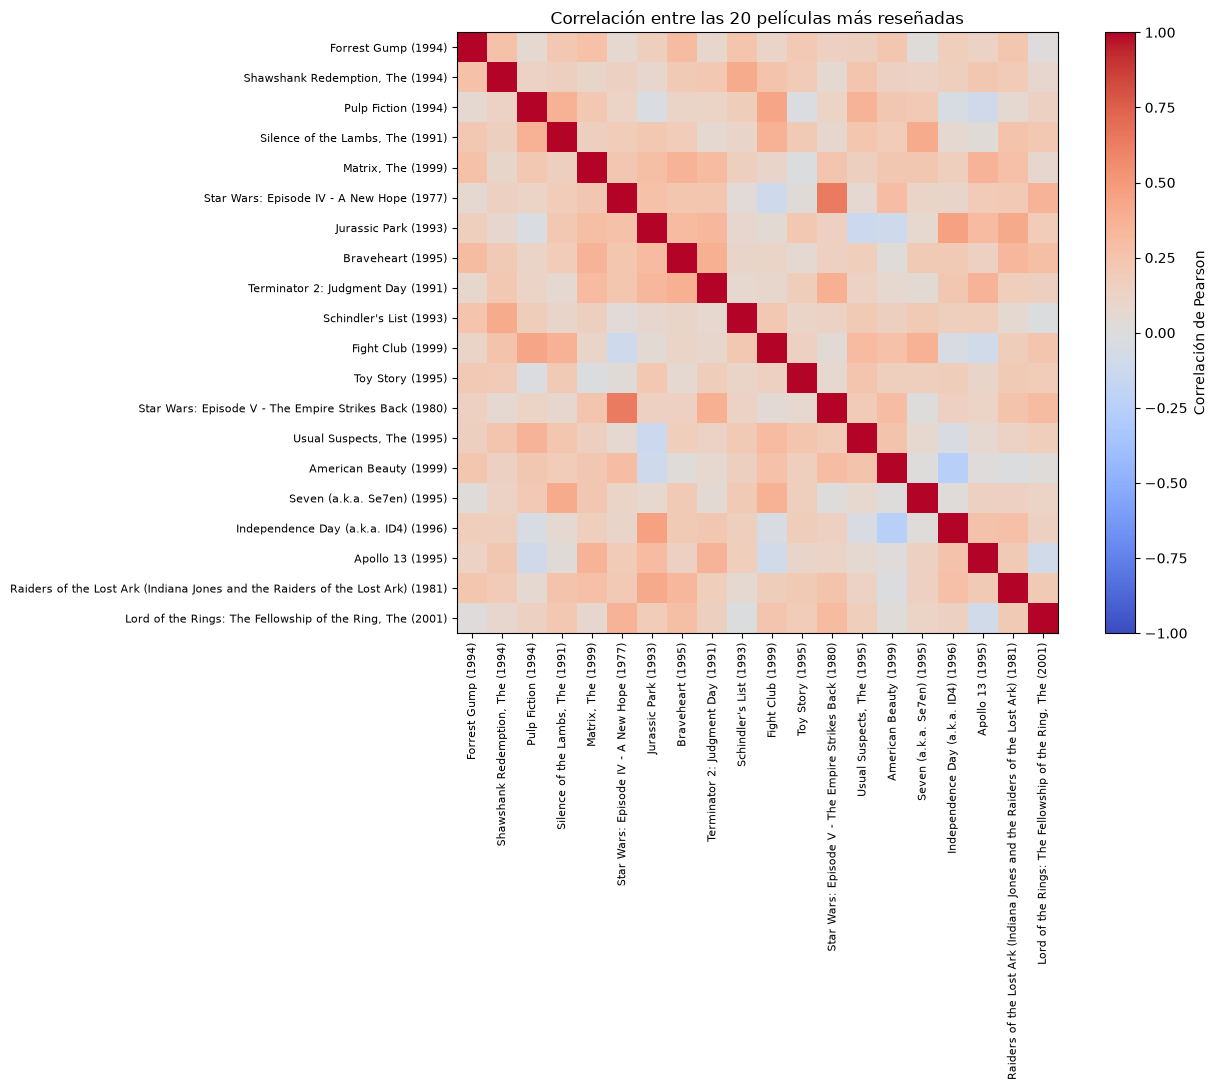

In [ ]:
# rutas.guardar_figura(fig, "03_heatmap_peliculas")

peliculas_heatmap = gustos.notna().sum().sort_values(
    ascending=False
).head(20).index

# Obtener sus correlaciones
correlaciones_heatmap = correlaciones.loc[
    peliculas_heatmap,
    peliculas_heatmap
]

# Recuperar los títulos
titulos = movies.set_index("movieId").loc[
    peliculas_heatmap, "title"
]

# Crear el gráfico
fig, ax = plt.subplots(figsize=(14, 11))

imagen = ax.imshow(
    correlaciones_heatmap,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(titulos)))
ax.set_yticks(range(len(titulos)))

ax.set_xticklabels(titulos, rotation=90, fontsize=8)
ax.set_yticklabels(titulos, fontsize=8)

ax.set_title("Correlación entre las 20 películas más reseñadas")
fig.colorbar(imagen, ax=ax, label="Correlación de Pearson")

plt.tight_layout()

# Guardar figura
rutas.guardar_figura(fig, "03_heatmap_peliculas")

plt.show()

> **Interpretación**
> - **Qué muestra:** La matriz de correlación de Pearson (coeficiente $\phi$ entre variables binarias) para las 20 películas con mayor número de calificaciones en el catálogo, evaluadas sobre usuarios que calificaron ambas ($min\_periods = 20$). La escala de colores va de azul (correlación negativa) a rojo (correlación positiva), centrada en blanco (0, independencia).
> - **Por qué es relevante:** Permite visualizar de forma condensada si las películas más populares comparten audiencias con patrones de afinidad comunes o si son evaluadas de manera independiente. Se observan bloques de correlación positiva moderada entre clásicos de acción y suspenso de la época (por ejemplo, *Die Hard* con *Reservoir Dogs*, $r \approx 0.28$, o *Die Hard* con *Toy Story*, $r \approx 0.31$), mientras que otros pares muestran ligera correlación negativa o independencia (como *GoldenEye* y *Toy Story*, $r = -0.14$).
> - **Limitaciones:** El gráfico se limita a las 20 películas más evaluadas, que por definición son películas comerciales de alta aceptación general, dejando fuera afinidades específicas de géneros de nicho o películas de culto. Además, la correlación lineal asume una relación simétrica entre ambas variables, sin capturar direccionalidad.


## 5. Probabilidades condicionales

La correlación nos permite identificar películas cuyos patrones de aceptación son similares, queremos conocer qué tan frecuente es que a un usuario le guste una película cuando sabemos que le gusta otra.

Para responder, calcularemos probabilidades condicionales entre las parejas de películas seleccionadas, haremos lo siguiente

- Consideraremos únicamente a los usuarios que calificaron ambas películas.

- Identificaremos a quienes disfrutaron la película de referencia (X).

- Calcularemos qué proporción de ellos también disfrutó la película Y.

La probabilidad que buscamos es:

$$

P(Y=1\mid X=1)

$$

Donde:

- \(X=1\): al usuario le gusta la película de referencia.
- \(Y=1\): al usuario también le gusta la película evaluada.

De esta manera podremos identificar posibles recomendaciones a partir de las preferencias que los usuarios ya han expresado.

In [ ]:
# para los 5 mejores pares: crosstab normalize='index' → P(le gusta Y | le gusta X) contra P(le gusta Y)

# Seleccionar las 5 parejas con mayor correlación
mejores_pares = pares_correlacion.head(5)

resultados = []
movies_idx = movies.set_index("movieId")

for _, par in mejores_pares.iterrows():

    pelicula_x = par["movieId_1"]
    pelicula_y = par["movieId_2"]

    # Seleccionar usuarios que calificaron ambas películas
    gustos_par = gustos[[pelicula_x, pelicula_y]].dropna()

    # Usuarios a quienes les gusta la película X
    usuarios_gustan_x = gustos_par[gustos_par[pelicula_x] == 1]

    # Probabilidad de que también les guste Y
    p_y_dado_x = usuarios_gustan_x[pelicula_y].mean()

    resultados.append({
        "pelicula_X": movies_idx.loc[pelicula_x, "title"],
        "pelicula_Y": movies_idx.loc[pelicula_y, "title"],
        "P(Y|X)": p_y_dado_x
    })

comparacion_probabilidades = pd.DataFrame(resultados)

comparacion_probabilidades.style.format({
    "P(Y|X)": "{:.2%}",
})

estilizado = comparacion_probabilidades.style.format({
    "P(Y|X)": "{:.2%}",
}).set_properties(**{
    "white-space": "normal",
    "max-width": "250px",
    'text-align': 'left',
    
})

display(estilizado)
print(f"La tabla se lee como la probabilidad de que a un usuario le guste la película Y dado que le gustó la película X.")
print(f"Por ejemplo, la probabilidad de que a un usuario le guste {comparacion_probabilidades.loc[0, 'pelicula_Y']} dado que le gustó {comparacion_probabilidades.loc[0, 'pelicula_X']} es de {comparacion_probabilidades.loc[0, 'P(Y|X)']:.2%}.")

,pelicula_X,pelicula_Y,P(Y|X)
0,"Lord of the Rings: The Two Towers, The (2002)","Lord of the Rings: The Return of the King, The (2003)",99.15%
1,Harry Potter and the Sorcerer's Stone (a.k.a. Harry Potter and the Philosopher's Stone) (2001),Harry Potter and the Chamber of Secrets (2002),84.44%
2,Kill Bill: Vol. 1 (2003),Kill Bill: Vol. 2 (2004),89.04%
3,"Lord of the Rings: The Fellowship of the Ring, The (2001)","Lord of the Rings: The Return of the King, The (2003)",96.80%
4,Harry Potter and the Chamber of Secrets (2002),Pretty Woman (1990),90.48%


La tabla se lee como la probabilidad de que a un usuario le guste la película Y dado que le gustó la película X.
Por ejemplo, la probabilidad de que a un usuario le guste Lord of the Rings: The Return of the King, The (2003) dado que le gustó Lord of the Rings: The Two Towers, The (2002) es de 99.15%.


## 6. Conclusiones y limitaciones

### Hallazgos principales

**1. Las películas de una misma saga muestran una afinidad importante entre sí.**

Entre las parejas con mayor correlación encontramos principalmente películas que pertenecen a una misma franquicia:

- *The Lord of the Rings: The Two Towers* y *The Lord of the Rings: The Return of the King* (\(r = 0.823\)).
- *Harry Potter and the Sorcerer's Stone* y *Harry Potter and the Chamber of Secrets* (\(r = 0.812\)).
- *Kill Bill: Vol. 1* y *Kill Bill: Vol. 2* (\(r = 0.785\)).
- *The Lord of the Rings: The Fellowship of the Ring* y *The Lord of the Rings: The Return of the King* (\(r = 0.761\)).
- *The Godfather* y *The Godfather: Part II* (\(r = 0.725\)).

Esto tiene sentido, ya que las películas de una misma saga suelen compartir personajes, historias y estilos. Por lo tanto, es común que quienes disfrutan una entrega también tengan una opinión similar sobre las demás. En los resultados podemos observar que esta relación se refleja en las correlaciones más altas.

**2. También encontramos afinidades entre películas que no pertenecen a una misma saga.**

No todas las relaciones importantes se dan entre películas directamente relacionadas. También encontramos parejas como:

- *Harry Potter and the Chamber of Secrets* y *Pretty Woman* (\(r = 0.750\)).
- *American Pie* y *Outbreak* (\(r = 0.741\)).
- *One Flew Over the Cuckoo's Nest* y *Interview with the Vampire* (\(r = 0.643\)).

Estos resultados son interesantes porque muestran que películas bastante diferentes pueden tener patrones de aceptación similares entre los usuarios. Aunque no podemos determinar con este análisis qué características explican esas coincidencias, sí podemos identificar que existen usuarios que comparten preferencias por esos títulos.

**3. La probabilidad de que también guste otra película depende de cuál sea la película de referencia.**

Además de las correlaciones, calculamos probabilidades condicionales para conocer qué proporción de los usuarios que disfrutan una película también disfruta otra.

Algunos de los resultados más destacados fueron:

- Entre los usuarios a quienes les gustó *The Lord of the Rings: The Two Towers*, el **99.15%** también disfrutó *The Return of the King*.
- Entre quienes disfrutaron *Harry Potter and the Sorcerer's Stone*, el **84.44%** también disfrutó *The Chamber of Secrets*.
- Entre quienes disfrutaron *Kill Bill: Vol. 1*, el **89.04%** también disfrutó *Kill Bill: Vol. 2*.

Estas cifras permiten entender mejor las relaciones encontradas. Por ejemplo, en el primer caso, prácticamente todos los usuarios que disfrutaron *The Two Towers* también calificaron positivamente *The Return of the King*.

Es importante mencionar que estas probabilidades se calcularon utilizando únicamente a los usuarios que calificaron ambas películas. De esta manera, la comparación se realiza sobre personas que expresaron su opinión respecto a los dos títulos.

**4. La matriz de correlaciones permitió analizar una gran parte de las parejas de películas seleccionadas.**

Trabajamos con 138 películas que contaban con al menos 100 calificaciones. A partir de ellas se podían formar 9,453 parejas, de las cuales 9,245 tuvieron una correlación definida, lo que representa aproximadamente el 97.8%.

Para calcular las correlaciones establecimos un mínimo de 20 usuarios compartidos por pareja. Esto permitió evitar cálculos con una cantidad demasiado pequeña de observaciones. Sin embargo, cumplir con ese mínimo no significa que todas las correlaciones tengan la misma precisión, ya que algunas parejas cuentan con muchos más usuarios compartidos que otras.

---

### Limitaciones del análisis

**1. Los usuarios no califican las películas de la misma manera.**

Para identificar si una película le gustó a un usuario establecimos como criterio una calificación mayor o igual a 4.0. Aunque esto permite trabajar con una clasificación uniforme, no todos los usuarios utilizan las calificaciones de la misma forma.

En los datos observamos que el porcentaje de calificaciones positivas por usuario presenta los siguientes valores:

- Media: **56.07%**.
- Mediana: **57.97%**.
- Desviación estándar: **20.23 puntos porcentuales**.
- Valores mínimo y máximo: **0% y 100%**.

Esto indica que algunos usuarios suelen otorgar calificaciones positivas con mayor frecuencia que otros. Por lo tanto, el mismo umbral puede representar distintos niveles de exigencia al momento de evaluar una película.

**2. No todos los usuarios califican las mismas películas.**

Los valores ausentes (`NaN`) corresponden a películas que un usuario no calificó. Esto representa una limitación porque no sabemos si no vio la película, si decidió no evaluarla o si simplemente no tuvo interés en ella.

Además, las películas que cada persona decide calificar pueden estar relacionadas con sus gustos e intereses. Por esta razón, los usuarios que calificaron dos películas no necesariamente representan al conjunto completo de usuarios.

**3. La cantidad de usuarios compartidos cambia entre parejas.**

Aunque establecimos un mínimo de 20 usuarios compartidos para calcular las correlaciones, la cantidad de observaciones puede variar considerablemente entre parejas.

Una correlación calculada con 20 usuarios puede ser más sensible a las preferencias de unos cuantos individuos que otra calculada con cientos de usuarios. Por ello, es importante considerar el tamaño de cada muestra al interpretar los resultados.

También debemos tener en cuenta que, al seleccionar únicamente películas con al menos 100 calificaciones, dejamos fuera títulos menos populares que podrían presentar relaciones interesantes.

**4. Los resultados muestran asociaciones, no relaciones de causa y efecto.**

Encontrar una correlación elevada entre dos películas no significa que disfrutar una provoque que también guste la otra.

Lo que observamos son preferencias que tienden a presentarse juntas entre los usuarios. Estas coincidencias pueden estar relacionadas con factores como los gustos personales, los géneros favoritos o los intereses cinematográficos de cada individuo, pero nuestro análisis no permite determinar cuál de ellos explica las relaciones encontradas.

---

### Conclusión general

A través de este análisis pudimos identificar que las preferencias de los usuarios no se presentan de manera aislada. Existen películas cuyos niveles de aceptación tienden a coincidir, especialmente cuando pertenecen a una misma saga, aunque también encontramos afinidades entre títulos que no tienen una relación directa.

Las probabilidades condicionales complementaron estos resultados al permitirnos responder una pregunta más concreta: si a una persona le gusta una película, ¿qué tan probable es que también le guste otra? Esto nos permitió pasar de observar qué películas tienen comportamientos similares a conocer qué proporción de usuarios comparte esas preferencias.

En conjunto, los resultados muestran que las calificaciones de los usuarios pueden utilizarse para encontrar afinidades entre películas y servir como base para desarrollar sistemas de recomendación. Sin embargo, estas relaciones deben interpretarse considerando que cada usuario tiene sus propios criterios para calificar, que no todos evalúan los mismos títulos y que la cantidad de observaciones disponibles varía entre parejas.